In [5]:
import pandas as pd
import re
from collections import Counter
import numpy as np

In [6]:

df = pd.read_csv("/content/Womens Clothing E-Commerce Reviews.csv")

In [7]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [8]:
df.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='object')

In [9]:
df.shape

(23486, 11)

In [10]:
df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [11]:
df.dtypes

,0
Unnamed: 0,int64
Clothing ID,int64
Age,int64
Title,object
Review Text,object
Rating,int64
Recommended IND,int64
Positive Feedback Count,int64
Division Name,object
Department Name,object


In [12]:
df.isnull().sum()

,0
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14


In [13]:
df = df.drop(columns=["Unnamed: 0"])

In [14]:
df

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...
23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [15]:
df.shape

(23486, 10)

In [16]:
df.columns

Index(['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='object')

In [17]:
df.isnull().sum()

,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14
Class Name,14


In [18]:
df = df.dropna(subset=["Review Text"])

In [19]:
df.shape

(22641, 10)

In [20]:
df["Division Name"] = df["Division Name"].fillna("Unknown")
df["Department Name"] = df["Department Name"].fillna("Unknown")
df["Class Name"] = df["Class Name"].fillna("Unknown")

/tmp/ipykernel_8764/4199491626.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Division Name"] = df["Division Name"].fillna("Unknown")
/tmp/ipykernel_8764/4199491626.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Department Name"] = df["Department Name"].fillna("Unknown")
/tmp/ipykernel_8764/4199491626.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation

In [21]:
df

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...
23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [22]:
df.columns

Index(['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='object')

In [23]:
df.isnull().sum()

,0
Clothing ID,0
Age,0
Title,2966
Review Text,0
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,0
Department Name,0
Class Name,0


In [24]:
df.duplicated().sum()

np.int64(1)

In [25]:
df = df.drop_duplicates()

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df.shape

(22640, 10)

##TEXT CLEANING


In [28]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [29]:
df["Cleaned Review"] = df["Review Text"].apply(clean_text)

/tmp/ipykernel_8764/3089892083.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Cleaned Review"] = df["Review Text"].apply(clean_text)


In [30]:
df[["Review Text", "Cleaned Review"]].head(10)

,Review Text,Cleaned Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...
1,Love this dress! it's sooo pretty. i happene...,love this dress it s sooo pretty i happened to...
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it s fun flirty...
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...
5,"I love tracy reese dresses, but this one is no...",i love tracy reese dresses but this one is not...
6,I aded this in my basket at hte last mintue to...,i aded this in my basket at hte last mintue to...
7,"I ordered this in carbon for store pick up, an...",i ordered this in carbon for store pick up and...
8,I love this dress. i usually get an xs but it ...,i love this dress i usually get an xs but it r...
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",i m and lbs i ordered the s petite to make sur...


##RATING ANALYSIS & CRITICAL REVIEWS


In [31]:
rating_counts = df["Rating"].value_counts().sort_index()
rating_counts

,count
Rating,
1,821
2,1549
3,2823
4,4908
5,12539


In [32]:
rating_percentages = df["Rating"].value_counts(normalize=True).sort_index() * 100
rating_percentages.round(2)

,proportion
Rating,
1,3.63
2,6.84
3,12.47
4,21.68
5,55.38


## Rating Distribution

The `Rating` column was analyzed to understand the distribution of customer ratings. The `value_counts()` method was used to count reviews for each rating from 1 to 5, and the percentage distribution was also calculated.

This helps us understand the overall feedback pattern before identifying critical reviews.

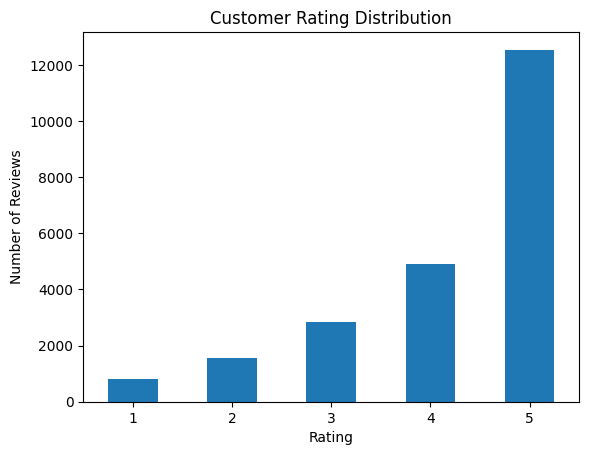

In [33]:
import matplotlib.pyplot as plt

rating_counts.plot(kind="bar")

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

## Rule-Based Critical Review Filtering

For this project, reviews with a rating of 1 or 2 stars are classified as critical reviews.

This is a rule-based approach and does not use Machine Learning or sentiment classification.

In [34]:
critical_reviews = df[df["Rating"].isin([1, 2])].copy()

In [35]:
critical_percentage = (len(critical_reviews) / len(df)) * 100
round(critical_percentage, 2)

10.47

## Critical Review Insight

Reviews with ratings of 1 or 2 stars were classified as critical using a rule-based approach.

The percentage of critical reviews was calculated by dividing the number of critical reviews by the total number of cleaned and unique reviews.

This allows the company to understand the proportion of customer feedback that requires closer attention.

In [36]:
critical_reviews[["Rating", "Title", "Review Text"]].head(10)

,Rating,Title,Review Text
5,2,Not for the very petite,"I love tracy reese dresses, but this one is no..."
22,2,Not what it looks like,"First of all, this is not pullover styling. th..."
26,2,Huge disappointment,I have been waiting for this sweater coat to s...
33,2,Mehh,"I ordered this 3 months ago, and it finally ca..."
56,2,NaN,I am pregnant and i thought this would be a gr...
61,1,Itchy tags,"3 tags sewn in, 2 small (about 1'' long) and 1..."
68,2,I wanted to love this top...,I really loved this top online and wanted to l...
71,2,Short and boxy,Why do designers keep making crop tops??!! i c...
77,2,Zipper broke,The zipper broke on this piece the first time ...
85,1,NaN,"I was really hoping to like this, but it did n..."


Separate 1-star and 2-star reviews

In [37]:
one_star_reviews = critical_reviews[critical_reviews["Rating"] == 1].copy()
two_star_reviews = critical_reviews[critical_reviews["Rating"] == 2].copy()

In [38]:
print("1-star reviews:", len(one_star_reviews))
print("2-star reviews:", len(two_star_reviews))

1-star reviews: 821
2-star reviews: 1549


## Complaint Keyword Analysis

A predefined list of complaint-related keywords is used to identify common issues mentioned in critical reviews. The keywords represent potential issues such as damaged products, delays, refunds, returns, customer service problems, and poor product quality.

In [39]:
complaint_keywords = [
    "broken",
    "damaged",
    "late",
    "delay",
    "delayed",
    "rude",
    "refund",
    "missing",
    "wrong",
    "poor",
    "bad",
    "unreliable",
    "replacement",
    "support",
    "customer service",
    "overpriced",
    "expensive",
    "return",
    "cancel",
    "disappointed"
]

In [40]:
keyword_counts = Counter()

for review in critical_reviews["Cleaned Review"]:
    for keyword in complaint_keywords:
        if keyword in review:
            keyword_counts[keyword] += 1

In [41]:
keyword_counts.most_common(10)

[('return', 499),
 ('disappointed', 252),
 ('bad', 128),
 ('poor', 91),
 ('wrong', 59),
 ('late', 22),
 ('expensive', 16),
 ('missing', 12),
 ('support', 10),
 ('overpriced', 9)]

In [42]:
keyword_df = pd.DataFrame(
    keyword_counts.most_common(10),
    columns=["Complaint Keyword", "Count"]
)

keyword_df

,Complaint Keyword,Count
0,return,499
1,disappointed,252
2,bad,128
3,poor,91
4,wrong,59
5,late,22
6,expensive,16
7,missing,12
8,support,10
9,overpriced,9


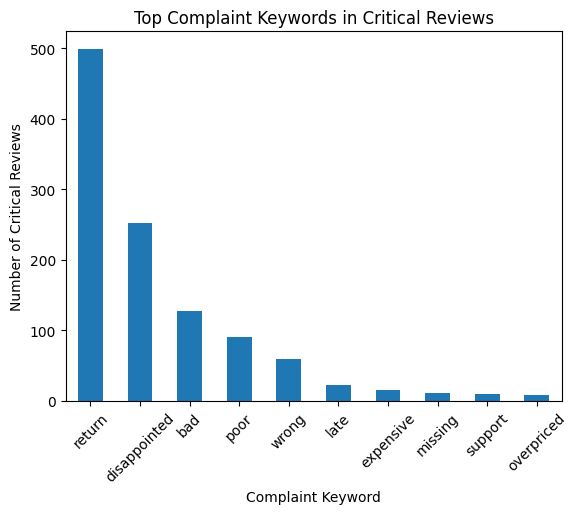

In [43]:
keyword_df.plot(
    x="Complaint Keyword",
    y="Count",
    kind="bar",
    legend=False
)

plt.title("Top Complaint Keywords in Critical Reviews")
plt.xlabel("Complaint Keyword")
plt.ylabel("Number of Critical Reviews")
plt.xticks(rotation=45)
plt.show()

In [44]:
one_star_reviews["Review Length"] = one_star_reviews["Cleaned Review"].str.len()

In [45]:
one_star_reviews = one_star_reviews.sort_values(
    "Review Length",
    ascending=False
)

In [46]:
top_3_reviews = one_star_reviews.head(3)

In [47]:
top_3_reviews[
    ["Rating", "Title", "Review Text", "Review Length"]
]

,Rating,Title,Review Text,Review Length
19304,1,I don't understand this dress,I have been continually disappointed in retail...,496
12663,1,Runs small would be a bit of an understatement...,It is a shame when a product such as this is l...,496
12155,1,So disappointing!,I was so excited to get this robe in the mail ...,495


## Selection of Top 3 Critical Reviews

For Generative AI outreach, the analysis focuses on 1-star reviews because they represent the lowest rating category in the dataset.

To identify detailed reviews, the character length of the cleaned review text was calculated. The three longest 1-star reviews were selected so that the Generative AI system receives sufficient customer-provided context when generating personalized responses.

This selection method is a rule-based heuristic used for this project.

In [48]:
rating_counts = df["Rating"].value_counts().sort_index()
rating_counts

,count
Rating,
1,821
2,1549
3,2823
4,4908
5,12539


In [49]:
critical_reviews = df[df["Rating"].isin([1, 2])].copy()
critical_reviews.shape

(2370, 11)

In [50]:
critical_percentage = (len(critical_reviews) / len(df)) * 100
round(critical_percentage, 2)

10.47

In [51]:
print("1-star reviews:", len(df[df["Rating"] == 1]))
print("2-star reviews:", len(df[df["Rating"] == 2]))

1-star reviews: 821
2-star reviews: 1549


## Complaint Keyword Analysis

Complaint-related keywords were defined to identify common issues mentioned in critical customer reviews. The analysis focuses on product problems, delivery issues, returns/refunds, and customer service complaints.

In [52]:
complaint_keywords = [
    "broken",
    "damaged",
    "late",
    "delay",
    "delayed",
    "rude",
    "refund",
    "missing",
    "wrong",
    "poor",
    "bad",
    "unreliable",
    "replacement",
    "support",
    "customer service",
    "overpriced",
    "expensive",
    "return",
    "cancel",
    "disappointed"
]

In [53]:
keyword_counts = Counter()

for review in critical_reviews["Cleaned Review"]:
    for keyword in complaint_keywords:
        if keyword in review:
            keyword_counts[keyword] += 1

In [54]:
keyword_counts.most_common(10)

[('return', 499),
 ('disappointed', 252),
 ('bad', 128),
 ('poor', 91),
 ('wrong', 59),
 ('late', 22),
 ('expensive', 16),
 ('missing', 12),
 ('support', 10),
 ('overpriced', 9)]

In [55]:
keyword_df = pd.DataFrame(
    keyword_counts.most_common(10),
    columns=["Complaint Keyword", "Count"]
)

keyword_df

,Complaint Keyword,Count
0,return,499
1,disappointed,252
2,bad,128
3,poor,91
4,wrong,59
5,late,22
6,expensive,16
7,missing,12
8,support,10
9,overpriced,9


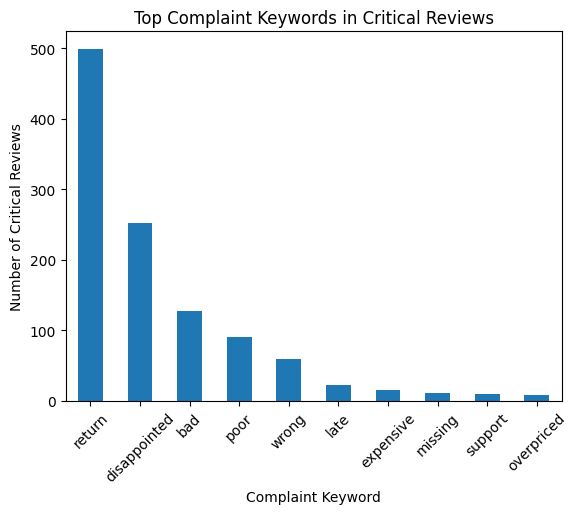

In [56]:
keyword_df.plot(
    x="Complaint Keyword",
    y="Count",
    kind="bar",
    legend=False
)

plt.title("Top Complaint Keywords in Critical Reviews")
plt.xlabel("Complaint Keyword")
plt.ylabel("Number of Critical Reviews")
plt.xticks(rotation=45)
plt.show()

In [57]:
one_star_reviews = critical_reviews[
    critical_reviews["Rating"] == 1
].copy()

In [58]:
one_star_reviews["Review Length"] = (
    one_star_reviews["Cleaned Review"].str.len()
)

In [59]:
one_star_reviews = one_star_reviews.sort_values(
    "Review Length",
    ascending=False
)

In [60]:
top_3_reviews = one_star_reviews.head(3)

In [61]:
top_3_reviews[
    ["Rating", "Title", "Review Text", "Review Length"]
]

,Rating,Title,Review Text,Review Length
19304,1,I don't understand this dress,I have been continually disappointed in retail...,496
12663,1,Runs small would be a bit of an understatement...,It is a shame when a product such as this is l...,496
12155,1,So disappointing!,I was so excited to get this robe in the mail ...,495


## Selection of Top 3 Critical Reviews

For the Generative AI outreach stage, 1-star reviews were considered because they represent the lowest rating category.

Among the 1-star reviews, the character length of the cleaned review was used as a simple heuristic for identifying detailed reviews. The three longest reviews were selected so that the Generative AI system receives sufficient customer-provided context when generating personalized responses.

## Generative AI – Automated Customer Outreach

The three most critical reviews were passed to a Generative AI model to generate short, personalized, and empathetic apology emails.

In [62]:
!pip install -q -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.5/263.5 kB 13.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.59.1 which is incompatible.


In [63]:
from google import genai
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini API connected successfully!")

Gemini API connected successfully!


### Generating an AI Response for a Critical Review

A Generative AI model is used to create a short, personalized, and empathetic apology email based on the customer's review.

In [64]:
review = top_3_reviews.iloc[0]["Review Text"]

print(review)

I have been continually disappointed in retailer's clothing for the past year. i feel like their prices have soared and the quality has remained so-so, but dresses like these somehow make the cut. it does not make sense. since when did retailer exclusively market to older women? no, retailer's market has always been young adults. this dress is extremely matronly. although the bottom print is nice, the hot pink belt?? is completely mismatched and gaudy. i really hope retailer starts curating better dress


In [65]:
prompt = f"""
You are a professional Customer Support Agent for an online clothing retailer.

A customer has submitted the following 1-star review:

"{review}"

Write a short, personalized and empathetic apology email to the customer.

Requirements:
- Acknowledge the customer's specific problem.
- Apologize sincerely.
- Show empathy.
- Do not blame the customer.
- Do not invent refunds, discounts, replacements, or other actions that were not mentioned.
- Keep the email concise and professional.
- Include a suitable subject line.
- End with a polite customer-support closing.

Return only the email.
"""

print(prompt)


You are a professional Customer Support Agent for an online clothing retailer.

A customer has submitted the following 1-star review:

"I have been continually disappointed in retailer's clothing for the past year. i feel like their prices have soared and the quality has remained so-so, but dresses like these somehow make the cut. it does not make sense. since when did retailer exclusively market to older women? no, retailer's market has always been young adults. this dress is extremely matronly. although the bottom print is nice, the hot pink belt?? is completely mismatched and gaudy. i really hope retailer starts curating better dress"

Write a short, personalized and empathetic apology email to the customer.

Requirements:
- Acknowledge the customer's specific problem.
- Apologize sincerely.
- Show empathy.
- Do not blame the customer.
- Do not invent refunds, discounts, replacements, or other actions that were not mentioned.
- Keep the email concise and professional.
- Include a s

In [68]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents=prompt
)

print(response.text)

Subject: Regarding your recent review of our dress collection

Dear Customer,

Thank you for taking the time to share your honest feedback with us. I am truly sorry to hear that your experience with our brand over the past year has been so disappointing, and that your recent dress purchase fell far short of your expectations. 

I completely understand your frustration with rising prices not matching product quality, as well as your concerns about our recent styling choices. You rely on us for fresh, modern designs, and we clearly missed the mark with this dress—especially with the mismatched hot pink belt detracting from what could have been a great piece. It is disheartening to know that you feel our collection has shifted away from the styles you originally came to love.

Please know that your feedback regarding our curation, design elements, and quality standards has been shared directly with our design and merchandising teams as they evaluate upcoming collections. 

Thank you again

## Automated AI Responses for Top 3 Critical Reviews

The selected 1-star reviews are processed individually using the Generative AI model. For each review, a personalized and empathetic customer-support apology email is generated.

In [70]:
import time

ai_responses = []

for index, row in top_3_reviews.iterrows():

    review = row["Review Text"]

    prompt = f"""
You are a professional Customer Support Agent for an online clothing retailer.

A customer has submitted the following 1-star review:

"{review}"

Write a short, personalized and empathetic apology email to the customer.

Requirements:
- Acknowledge the customer's specific problem.
- Apologize sincerely.
- Show empathy.
- Do not blame the customer.
- Do not invent refunds, discounts, replacements, or other actions.
- Keep the email concise and professional.
- Include a suitable subject line.
- End with a polite customer-support closing.

Return only the email.
"""

    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model="gemini-3.5-flash",
                contents=prompt
            )

            ai_responses.append(response.text)
            break

        except Exception as e:
            if attempt < 2:
                print(f"Temporary API error. Retrying review {len(ai_responses)+1}...")
                time.sleep(5)
            else:
                raise e

print("AI responses generated successfully!")

AI responses generated successfully!


In [71]:
response_df = top_3_reviews[
    ["Rating", "Title", "Review Text"]
].copy()

response_df["AI Generated Response"] = ai_responses

response_df[
    ["Rating", "Title", "AI Generated Response"]
]

,Rating,Title,AI Generated Response
19304,1,I don't understand this dress,Subject: We hear you: Feedback regarding your ...
12663,1,Runs small would be a bit of an understatement...,Subject: Regarding your recent feedback - We a...
12155,1,So disappointing!,Subject: We are so sorry about your recent ord...


In [72]:
for i, response in enumerate(ai_responses, start=1):
    print(f"\n{'='*70}")
    print(f"AI-GENERATED CUSTOMER RESPONSE {i}")
    print(f"{'='*70}")
    print(response)


AI-GENERATED CUSTOMER RESPONSE 1
Subject: We hear you: Feedback regarding your recent purchase

Dear [Customer Name],

Thank you for sharing your honest feedback with us. I am truly sorry to hear that we have disappointed you over the past year, and especially with your recent dress purchase. 

I completely understand your frustration regarding the rise in our prices without a matching increase in quality. We always want our customers to feel they are getting excellent value. I also appreciate your specific feedback about the design of the dress; I hear you that the style felt overly matronly for our young adult audience, and that the hot pink belt felt gaudy and mismatched against the print. 

As a valued customer, your styling expectations are incredibly important to us. Please know that I have shared your comments directly with our design and curation teams so we can work on delivering the high-quality, on-trend styles you expect and deserve from us. 

Thank you again for taking th